Dataset Loaded: (50000, 32, 32, 3)
Epoch 1/100


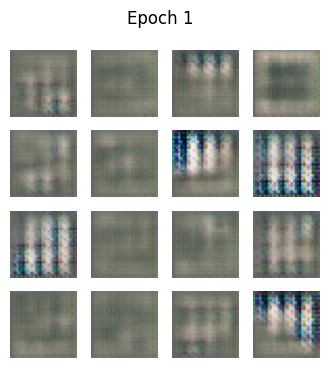

Epoch 2/100
Epoch 3/100
Epoch 4/100
Epoch 5/100
Epoch 6/100
Epoch 7/100
Epoch 8/100
Epoch 9/100
Epoch 10/100
Epoch 11/100
Epoch 12/100
Epoch 13/100
Epoch 14/100
Epoch 15/100
Epoch 16/100
Epoch 17/100
Epoch 18/100
Epoch 19/100
Epoch 20/100
Epoch 21/100
Epoch 22/100
Epoch 23/100
Epoch 24/100
Epoch 25/100
Epoch 26/100
Epoch 27/100
Epoch 28/100
Epoch 29/100
Epoch 30/100
Epoch 31/100
Epoch 32/100
Epoch 33/100
Epoch 34/100
Epoch 35/100
Epoch 36/100
Epoch 37/100
Epoch 38/100
Epoch 39/100
Epoch 40/100
Epoch 41/100
Epoch 42/100
Epoch 43/100
Epoch 44/100
Epoch 45/100
Epoch 46/100
Epoch 47/100
Epoch 48/100
Epoch 49/100
Epoch 50/100


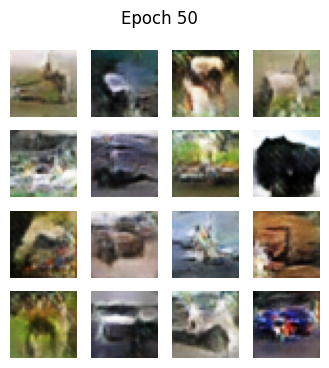

FID Score: 131.62
Epoch 51/100
Epoch 52/100
Epoch 53/100
Epoch 54/100
Epoch 55/100
Epoch 56/100
Epoch 57/100
Epoch 58/100
Epoch 59/100
Epoch 60/100
Epoch 61/100
Epoch 62/100
Epoch 63/100
Epoch 64/100
Epoch 65/100
Epoch 66/100
Epoch 67/100
Epoch 68/100
Epoch 69/100
Epoch 70/100
Epoch 71/100
Epoch 72/100
Epoch 73/100
Epoch 74/100
Epoch 75/100
Epoch 76/100
Epoch 77/100
Epoch 78/100
Epoch 79/100
Epoch 80/100
Epoch 81/100
Epoch 82/100
Epoch 83/100
Epoch 84/100
Epoch 85/100
Epoch 86/100
Epoch 87/100
Epoch 88/100
Epoch 89/100
Epoch 90/100
Epoch 91/100
Epoch 92/100
Epoch 93/100
Epoch 94/100
Epoch 95/100
Epoch 96/100
Epoch 97/100
Epoch 98/100
Epoch 99/100
Epoch 100/100


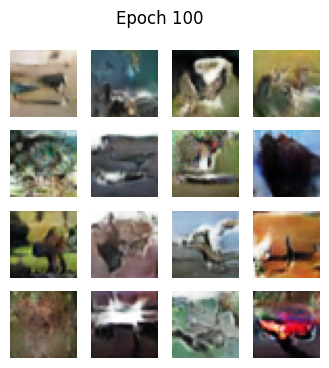

FID Score: 114.27
Training Completed Successfully


In [ ]:
# ==========================================
# DCGAN for CIFAR-10
# ==========================================

import tensorflow as tf
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications.inception_v3 import InceptionV3, preprocess_input
from scipy.linalg import sqrtm

# =========================
# Config
# =========================
BUFFER_SIZE = 50000
BATCH_SIZE = 128
EPOCHS = 100
NOISE_DIM = 100

# =========================
# Load CIFAR-10 Dataset
# =========================
(x_train, _), (_, _) = tf.keras.datasets.cifar10.load_data()
x_train = (x_train - 127.5) / 127.5  # Normalize [-1,1]

dataset = tf.data.Dataset.from_tensor_slices(x_train)\
    .shuffle(BUFFER_SIZE)\
    .batch(BATCH_SIZE, drop_remainder=True)\
    .prefetch(tf.data.AUTOTUNE)

print("Dataset Loaded:", x_train.shape)

# =========================
# Generator
# =========================
def build_generator():
    return tf.keras.Sequential([
        layers.Dense(4*4*512, use_bias=False, input_shape=(NOISE_DIM,)),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Reshape((4,4,512)),

        layers.Conv2DTranspose(256,4,2,'same',use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(128,4,2,'same',use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2DTranspose(64,4,2,'same',use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(),

        layers.Conv2D(3,3,padding='same',activation='tanh')
    ])

# =========================
# Discriminator
# =========================
def build_discriminator():
    return tf.keras.Sequential([
        layers.Conv2D(64,4,2,'same',input_shape=(32,32,3)),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(128,4,2,'same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Conv2D(256,4,2,'same'),
        layers.LeakyReLU(),
        layers.Dropout(0.3),

        layers.Flatten(),
        layers.Dense(1, activation='sigmoid')
    ])

generator = build_generator()
discriminator = build_discriminator()

# =========================
# Loss & Optimizers
# =========================
loss_fn = tf.keras.losses.BinaryCrossentropy()

gen_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)
disc_opt = tf.keras.optimizers.Adam(2e-4, beta_1=0.5)

# =========================
# Training Step (FIXED)
# =========================
@tf.function
def train_step(images):

    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])

    # ✅ FIXED LABEL SHAPE
    real_labels = tf.ones((BATCH_SIZE,1)) * 0.9
    fake_labels = tf.zeros((BATCH_SIZE,1))

    with tf.GradientTape() as gen_tape, tf.GradientTape() as disc_tape:

        fake_images = generator(noise, training=True)

        real_out = discriminator(images, training=True)
        fake_out = discriminator(fake_images, training=True)

        # Generator loss
        gen_loss = loss_fn(tf.ones((BATCH_SIZE,1)), fake_out)

        # Discriminator loss
        disc_loss = loss_fn(real_labels, real_out) + loss_fn(fake_labels, fake_out)

    gen_grad = gen_tape.gradient(gen_loss, generator.trainable_variables)
    disc_grad = disc_tape.gradient(disc_loss, discriminator.trainable_variables)

    gen_opt.apply_gradients(zip(gen_grad, generator.trainable_variables))
    disc_opt.apply_gradients(zip(disc_grad, discriminator.trainable_variables))

# =========================
# Image Visualization
# =========================
def show_images(epoch, seed):
    preds = generator(seed, training=False)
    preds = (preds + 1)/2

    plt.figure(figsize=(4,4))
    for i in range(16):
        plt.subplot(4,4,i+1)
        plt.imshow(preds[i])
        plt.axis("off")

    plt.suptitle(f"Epoch {epoch}")
    plt.show()

# =========================
# FID Model
# =========================
fid_model = InceptionV3(include_top=False, pooling='avg', input_shape=(299,299,3))

def calculate_fid():
    noise = tf.random.normal([500, NOISE_DIM])
    fake = generator(noise, training=False)

    real = tf.image.resize(x_train[:500], (299,299))
    fake = tf.image.resize(fake, (299,299))

    real = preprocess_input((real+1)*127.5)
    fake = preprocess_input((fake+1)*127.5)

    act1 = fid_model.predict(real, verbose=0)
    act2 = fid_model.predict(fake, verbose=0)

    mu1, sigma1 = act1.mean(0), np.cov(act1,rowvar=False)
    mu2, sigma2 = act2.mean(0), np.cov(act2,rowvar=False)

    covmean = sqrtm(sigma1.dot(sigma2))
    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = np.sum((mu1-mu2)**2) + np.trace(sigma1 + sigma2 - 2*covmean)
    return fid

# =========================
# Training Loop
# =========================
seed = tf.random.normal([16, NOISE_DIM])

for epoch in range(1, EPOCHS+1):

    for batch in dataset:
        train_step(batch)

    print(f"Epoch {epoch}/{EPOCHS}")

    # Show only required epochs
    if epoch in [1, EPOCHS//2, EPOCHS]:
        show_images(epoch, seed)

    # FID only mid & final
    if epoch in [EPOCHS//2, EPOCHS]:
        fid = calculate_fid()
        print(f"FID Score: {fid:.2f}")

print("Training Completed Successfully")